In [13]:
import numpy as np
import matplotlib.pyplot as plt
import time

## Sistemi lineari

Supponiamo di avere il seguente sistema lineare
$$
\begin{cases}
​x+y+z=6 \\
2x−y+z=3\\
x+2y−z=2​
\end{cases}
$$

In [4]:
A = np.array([[1.,  1.,  1.],
              [2., -1.,  1.],
              [1.,  2., -1.]])

b = np.array([6., 3., 2.])

print("A =")
print(A)

print("\nb =")
print(b)

A =
[[ 1.  1.  1.]
 [ 2. -1.  1.]
 [ 1.  2. -1.]]

b =
[6. 3. 2.]


In [5]:
# Matrice aumentata
Ab = np.column_stack((A, b))

print(Ab)

[[ 1.  1.  1.  6.]
 [ 2. -1.  1.  3.]
 [ 1.  2. -1.  2.]]


In [6]:
M = Ab.copy()

# R2 --> R2-2R1
M[1] = M[1] - 2 * M[0]

# R3 --> R3-R1
M[2] = M[2] - M[0]

print(M)

[[ 1.  1.  1.  6.]
 [ 0. -3. -1. -9.]
 [ 0.  1. -2. -4.]]


In [ ]:
# R3 --> 3R3+R2
M[2] = 3 * M[2] + M[1]

print(M)

[[  1.   1.   1.   6.]
 [  0.  -3.  -1.  -9.]
 [  0.   0.  -7. -21.]]


Il sistema diventa
$$
\begin{cases}
x+y+z=6 \\
-3y-z=-9 \\
-7z=-21
\end{cases}
$$

Sostituendo otteniamo

$$
x=1,\qquad y=2,\qquad z=3.
$$

Quello che abbiamo appena fatto a mano è il principio su cui si basano gli algoritmi 
per risolvere sistemi lineari. Le librerie usano versioni più sofisticate e robuste, 
ma l'idea è non dover eliminare manualmente centinaia di righe.

In [ ]:
A = np.array([[1.,  1.,  1.],
              [2., -1.,  1.],
              [1.,  2., -1.]])

b = np.array([6., 3., 2.])

x = np.linalg.solve(A, b)

print(x)

[1. 2. 3.]


In [ ]:
n = 1000

A_big = np.random.random((n, n))
b_big = np.random.random(n)

start = time.perf_counter()

x_big = np.linalg.solve(A_big, b_big)

elapsed = time.perf_counter() - start

print(f"Sistema: {n} equazioni in {n} incognite")
print(f"Tempo: {elapsed:.3f} s")

Sistema: 1000 equazioni in 1000 incognite
Tempo: 0.020 s


In [10]:
error = np.linalg.norm(A_big @ x_big - b_big)

print(f"Errore: {error:.2e}")

Errore: 3.83e-12


In [ ]:
sizes = [10, 100, 500, 1000, 2000]
times = []

for n in sizes:

    A = np.random.random((n, n))
    b = np.random.random(n)

    start = time.perf_counter()
    x = np.linalg.solve(A, b)
    elapsed = time.perf_counter() - start

    times.append(elapsed)

    print(f"{n:4d} x {n:4d}  ->  {elapsed:.4f} s")

  10 x   10  ->  0.0001 s
 100 x  100  ->  0.0002 s
 500 x  500  ->  0.0041 s
1000 x 1000  ->  0.0187 s
2000 x 2000  ->  0.1268 s


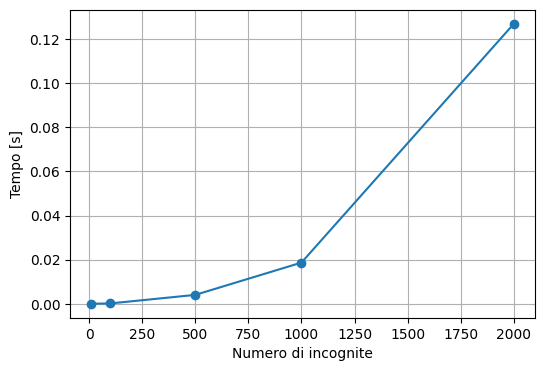

In [14]:
plt.figure(figsize=(6, 4))

plt.plot(sizes, times, "o-")

plt.xlabel("Numero di incognite")
plt.ylabel("Tempo [s]")
plt.grid()

plt.show()

Più il sistema diventa grande, più lavoro deve fare il computer. Ma siamo comunque in grado di risolvere automaticamente sistemi che a mano sarebbero completamente impossibili da affrontare.